<a href="https://colab.research.google.com/github/eltadlll/Quantizer_from_scratch/blob/main/Model_Quantizer_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Build  Model Quantizer: a from-scratch PyTorch project
**Model:** Qwen2.5-0.5B  |  **Method:** weight-only post-training quantization written in raw PyTorch (no bitsandbytes, no `torch.ao.quantization`)

This single notebook is the whole project. It runs top to bottom and does everything itself: builds the quantizer, checks it, runs 7 configurations,
draws the charts, saves the CSV tables, picks a winner, and exports the winner so it can be published on Hugging Face.


Two kinds of files are written: the results `.csv` tables and the `hf_model/` folder that Hugging Face needs.

| Section | What happens |
|---|---|
| 1 | Setup and the project constraint |
| 2 | The quantizer, built step by step |
| 3 | Sanity checks (tests inside the notebook) |
| 4 | Load the model and the evaluation data |
| 5 | Explore the weights (why scaling choices matter) |
| 6 | Run all 7 experiments |
| 7 | Visualisations |
| 8 | Pick the winner |
| 9 | Export and publish the quantized model |

## 1. Setup and the project constraint

In [1]:
!pip install -q transformers datasets safetensors huggingface_hub

In [2]:
import copy, json, math, os, statistics, time
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float16 if device.type == "cuda" else torch.float32
GPU_NAME = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print("device:", GPU_NAME, "| torch", torch.__version__)

device: Tesla T4 | torch 2.11.0+cu130


In [3]:
# ----------------------------- PROJECT SETTINGS (edit here) -----------------------------
MODEL_ID    = "Qwen/Qwen2.5-0.5B"   # small open-source model
SIZE_TARGET = 0.60                  # constraint (a): at least 60% smaller than FP16
PPL_TOL     = 0.15                  # constraint (b): perplexity at most +15% vs FP16
SEQ_LEN, BATCH_SIZE = 512, 4        # perplexity windows
MAX_EVAL_TOKENS = 0                 # 0 = whole WikiText-2 test set; e.g. 100_000 for a faster run
SPEED_TOKENS, SPEED_RUNS = 128, 3   # decoding speed test
HF_REPO_ID  = "EliasTad/qwen2.5-0.5b-w4-custom-quant"   # username/model-name (not a URL)
QUICK_TEST  = False                 # True = 1-minute dry run on a tiny random model (no downloads)
# -----------------------------------------------------------------------------------------
print(f"Constraint: >= {SIZE_TARGET:.0%} smaller than FP16 AND perplexity within +{PPL_TOL:.0%} of FP16")

Constraint: >= 60% smaller than FP16 AND perplexity within +15% of FP16


### A 2-minute primer on quantization
A weight `w` is stored as a small integer `q` plus a *scale* `s` (and a *zero-point* `z`), and recovered when needed:

```
s = (max - min) / (2^bits - 1)           z = round(-min / s)
q = clamp( round(w / s) + z, 0, 2^bits - 1 )          w_hat = (q - z) * s
```
Rounding error is at most half a step (`s/2`). What matters is **how many weights share one scale**:
*per-tensor* (one for the whole matrix), *per-channel* (one per output row) or *group-wise* (one per 64/128 weights).
One outlier weight stretches the range and coarsens the step for everything that shares its scale.
Real **bit-packing** (two 4-bit values per byte, four 2-bit values per byte) is used, so the reported size is honest.

## 2. The quantizer, built step by step
Everything below is plain PyTorch tensor math.

### 2.1 Configuration
`QConfig` describes a scheme as data. `CONFIGS` holds the 7 experiments; `EMBED_CFG` is the 8-bit scheme used for the embedding table in every experiment.

In [4]:
EPS = 1e-6
CLIP_GRID = [1.0 - 0.025 * i for i in range(13)]  # 1.0 ... 0.7 of the min/max range

# --------------------------------------------------------------------------- #
# Configuration
# --------------------------------------------------------------------------- #
@dataclass(frozen=True)
class QConfig:
    name: str
    bits: int = 4
    granularity: str = "per_channel"  # "per_tensor" | "per_channel" | "group"
    group_size: int = 128             # only used when granularity == "group"
    symmetric: bool = False           # False -> asymmetric with a zero-point
    clip_search: bool = False         # pick per-row clipping range minimising MSE

    def __post_init__(self):
        assert self.bits in (2, 4, 8), "bits must be 2, 4 or 8 (they pack evenly into a byte)"
        assert self.granularity in ("per_tensor", "per_channel", "group")

    @property
    def label(self) -> str:
        g = {"per_tensor": "per-tensor", "per_channel": "per-channel",
             "group": f"group-{self.group_size}"}[self.granularity]
        return f"W{self.bits} {g}" + (" +clip" if self.clip_search else "")

    @property
    def scheme(self) -> str:
        return "sym" if self.symmetric else "asym"


CONFIGS = {c.name: c for c in [
    QConfig("w8_per_tensor", 8, "per_tensor", symmetric=True),
    QConfig("w8_per_channel", 8, "per_channel", symmetric=True),
    QConfig("w4_per_tensor", 4, "per_tensor"),
    QConfig("w4_per_channel", 4, "per_channel"),
    QConfig("w4_g128", 4, "group", 128),
    QConfig("w4_g128_clip", 4, "group", 128, clip_search=True),
    QConfig("w2_g64", 2, "group", 64),
]}

# Embedding / tied lm_head table: always 8-bit per-row (same for every experiment,
# so the comparison between configs is only about the transformer-block linears).
EMBED_CFG = QConfig("embed_w8", 8, "per_channel", symmetric=True)

### 2.2 Core math: rows, quantize, clip search, pack / unpack
Every granularity is reduced to the same operation: *quantize the rows of a 2-D matrix*. `to_rows` reshapes a weight matrix so that all weights sharing a scale lie on one row.

In [5]:
# --------------------------------------------------------------------------- #
# Core math
# --------------------------------------------------------------------------- #
def layout(out_f: int, in_f: int, cfg: QConfig):
    """Return (n_rows, row_len, pad): the 2-D view where every row shares one scale."""
    if cfg.granularity == "per_tensor":
        return 1, out_f * in_f, 0
    if cfg.granularity == "per_channel":
        return out_f, in_f, 0
    g = cfg.group_size
    pad = (-in_f) % g
    return out_f * ((in_f + pad) // g), g, pad


def to_rows(w: torch.Tensor, cfg: QConfig):
    out_f, in_f = w.shape
    n_rows, row_len, pad = layout(out_f, in_f, cfg)
    if pad:
        w = F.pad(w, (0, pad))
    return w.reshape(n_rows, row_len), pad


def _quant_given_range(rows, bits, symmetric, lo, hi):
    """Quantize with an explicit range. Returns (q, scale, zero) as fp32 tensors."""
    if symmetric:
        qmax = 2 ** (bits - 1) - 1
        scale = (hi / qmax).clamp_min(EPS).half().float()      # scale is stored as fp16
        zero = torch.full_like(scale, 2 ** (bits - 1))          # constant offset -> unsigned storage
        q = torch.round(rows / scale).clamp(-qmax, qmax) + zero
    else:
        qmax = 2 ** bits - 1
        scale = ((hi - lo) / qmax).clamp_min(EPS).half().float()
        zero = torch.round(-lo / scale).clamp(0, qmax)
        q = (torch.round(rows / scale) + zero).clamp(0, qmax)
    return q, scale, zero


def _quantize_chunk(rows: torch.Tensor, cfg: QConfig):
    rows = rows.float()
    if cfg.symmetric:
        lo, hi = None, rows.abs().amax(1, keepdim=True)
    else:
        lo = rows.amin(1, keepdim=True).clamp(max=0)
        hi = rows.amax(1, keepdim=True).clamp(min=0)

    if not cfg.clip_search:
        q, scale, zero = _quant_given_range(rows, cfg.bits, cfg.symmetric, lo, hi)
    else:  # try shrinking the range; keep whichever shrink gives the lowest error per row
        best_err, q, scale, zero = None, None, None, None
        for p in CLIP_GRID:
            q_p, s_p, z_p = _quant_given_range(
                rows, cfg.bits, cfg.symmetric, None if lo is None else lo * p, hi * p)
            err = (((q_p - z_p) * s_p - rows) ** 2).sum(1, keepdim=True)
            if best_err is None:
                best_err, q, scale, zero = err, q_p, s_p, z_p
            else:
                m = err < best_err
                best_err = torch.where(m, err, best_err)
                q, scale, zero = (torch.where(m, q_p, q), torch.where(m, s_p, scale),
                                  torch.where(m, z_p, zero))
    return q.to(torch.uint8), scale.squeeze(1).half(), zero.squeeze(1).to(torch.uint8)


def quantize_rows(rows: torch.Tensor, cfg: QConfig, chunk_elems: int = 1 << 24):
    """Quantize a [R, L] matrix row by row (chunked to bound peak memory)."""
    R, L = rows.shape
    step = max(1, chunk_elems // L)
    parts = [_quantize_chunk(rows[i:i + step], cfg) for i in range(0, R, step)]
    q = torch.cat([p[0] for p in parts])
    scale = torch.cat([p[1] for p in parts])
    zero = None if cfg.symmetric else torch.cat([p[2] for p in parts])
    return q, scale, zero


def pack(q_flat: torch.Tensor, bits: int) -> torch.Tensor:
    """Pack a flat uint8 tensor of `bits`-bit values into bytes."""
    if bits == 8:
        return q_flat.contiguous()
    per = 8 // bits
    pad = (-q_flat.numel()) % per
    if pad:
        q_flat = F.pad(q_flat, (0, pad))
    q = q_flat.view(-1, per)
    out = torch.zeros(q.shape[0], dtype=torch.uint8, device=q.device)
    for i in range(per):
        out |= q[:, i] << (bits * i)
    return out


def unpack(packed: torch.Tensor, bits: int, numel: int) -> torch.Tensor:
    if bits == 8:
        return packed[:numel]
    per, mask = 8 // bits, (1 << bits) - 1
    parts = [(packed >> (bits * i)) & mask for i in range(per)]
    return torch.stack(parts, dim=1).reshape(-1)[:numel]

### 2.3 Modules: `QuantLinear` and `QuantEmbedding`
`QuantLinear` stores packed integers, FP16 scales and zero-points, and dequantizes on the fly in `forward`. `QuantEmbedding` shares the tied embedding/output-head tensors, so they are stored only once.

In [6]:
# --------------------------------------------------------------------------- #
# Modules
# --------------------------------------------------------------------------- #
class QuantLinear(nn.Module):
    """Linear layer that stores packed integer weights and dequantizes on the fly."""

    def __init__(self, in_features, out_features, cfg: QConfig, bias=False,
                 bias_dtype=torch.float16, device=None):
        super().__init__()
        self.in_features, self.out_features, self.cfg = in_features, out_features, cfg
        self.n_rows, self.row_len, self.pad = layout(out_features, in_features, cfg)
        per = 8 // cfg.bits
        n_bytes = math.ceil(self.n_rows * self.row_len / per)
        self.register_buffer("qweight", torch.zeros(n_bytes, dtype=torch.uint8, device=device))
        self.register_buffer("scale", torch.zeros(self.n_rows, dtype=torch.float16, device=device))
        if cfg.symmetric:
            self.register_buffer("zero", None)
        else:
            self.register_buffer("zero", torch.zeros(self.n_rows, dtype=torch.uint8, device=device))
        self.register_buffer("bias", torch.zeros(out_features, dtype=bias_dtype, device=device)
                             if bias else None)
        self.stats = None  # (squared error, squared norm) - only filled by from_float

    @classmethod
    def from_float(cls, weight: torch.Tensor, bias, cfg: QConfig):
        w = weight.detach()
        out_f, in_f = w.shape
        rows, _ = to_rows(w.float(), cfg)
        q, scale, zero = quantize_rows(rows, cfg)
        mod = cls(in_f, out_f, cfg, bias=bias is not None,
                  bias_dtype=bias.dtype if bias is not None else torch.float16, device=w.device)
        mod.qweight = pack(q.flatten(), cfg.bits)
        mod.scale = scale
        if zero is not None:
            mod.zero = zero
        if bias is not None:
            mod.bias = bias.detach().clone()
        deq = mod.dequantize(torch.float32)
        mod.stats = (((w.float() - deq) ** 2).sum().item(), (w.float() ** 2).sum().item())
        return mod

    def dequantize(self, dtype=torch.float16) -> torch.Tensor:
        q = unpack(self.qweight, self.cfg.bits, self.n_rows * self.row_len)
        q = q.reshape(self.n_rows, self.row_len).float()
        zero = (self.zero.float().unsqueeze(1) if self.zero is not None
                else float(2 ** (self.cfg.bits - 1)))
        w = (q - zero) * self.scale.float().unsqueeze(1)
        w = w.reshape(self.out_features, self.in_features + self.pad)[:, : self.in_features]
        return w.to(dtype)

    def forward(self, x):
        b = None if self.bias is None else self.bias.to(x.dtype)
        return F.linear(x, self.dequantize(x.dtype), b)

    def extra_repr(self):
        return f"in={self.in_features}, out={self.out_features}, {self.cfg.label} ({self.cfg.scheme})"


class QuantEmbedding(nn.Module):
    """8-bit per-row embedding table. For tied models it *shares* the tensors of the
    quantized lm_head (owns=False), so nothing is stored twice."""

    def __init__(self, ql: QuantLinear, owns: bool, out_dtype=torch.float16):
        super().__init__()
        assert ql.cfg.bits == 8 and ql.cfg.granularity == "per_channel" and ql.cfg.symmetric
        self.num_embeddings, self.embedding_dim = ql.out_features, ql.in_features
        self.out_dtype, self._owns = out_dtype, owns
        if owns:
            self.ql = ql
        else:
            object.__setattr__(self, "_ql_ref", ql)  # plain reference, not a registered child

    @property
    def _src(self):
        return self.ql if self._owns else self._ql_ref

    def forward(self, ids):
        src = self._src
        q = src.qweight.view(self.num_embeddings, self.embedding_dim)[ids].float()
        s = src.scale[ids].unsqueeze(-1).float()
        return ((q - 128.0) * s).to(self.out_dtype)

### 2.4 Whole-model conversion and size accounting
`convert` swaps every `nn.Linear` for a `QuantLinear` and collects error statistics. `model_size_bytes` counts the bytes of every distinct tensor actually stored.

In [7]:
# --------------------------------------------------------------------------- #
# Whole-model conversion
# --------------------------------------------------------------------------- #
def _set_module(model, name, new):
    parent = model
    *path, last = name.split(".")
    for p in path:
        parent = getattr(parent, p)
    setattr(parent, last, new)


def convert(model, cfg: QConfig, quantize_embeddings=True, with_weights=True):
    """Replace every nn.Linear in the transformer with QuantLinear (in place).

    with_weights=False builds empty QuantLinear shells (used when loading a saved model).
    Returns a dict of quantization statistics over the transformer-block linears.
    """
    out_dtype = next(model.parameters()).dtype
    emb, head = model.get_input_embeddings(), model.get_output_embeddings()
    tied = head is not None and head.weight is emb.weight
    head_name = next((n for n, m in model.named_modules() if m is head), None) if head is not None else None

    sq_err = sq_norm = numel = q_bytes = 0
    layers = []
    targets = [(n, m) for n, m in model.named_modules() if isinstance(m, nn.Linear) and m is not head]
    for name, m in targets:
        if with_weights:
            ql = QuantLinear.from_float(m.weight, m.bias, cfg)
            e, n2 = ql.stats
            sq_err, sq_norm = sq_err + e, sq_norm + n2
            layers.append({"name": name, "numel": m.weight.numel(),
                           "sqnr_db": 10 * math.log10(max(n2, 1e-30) / max(e, 1e-30))})
        else:
            ql = QuantLinear(m.in_features, m.out_features, cfg, bias=m.bias is not None,
                             bias_dtype=out_dtype, device=m.weight.device)
        numel += m.in_features * m.out_features
        q_bytes += sum(t.numel() * t.element_size() for t in (ql.qweight, ql.scale, ql.zero) if t is not None)
        _set_module(model, name, ql)

    if quantize_embeddings:
        def make(weight, bias, shape_src):
            if with_weights:
                return QuantLinear.from_float(weight, bias, EMBED_CFG)
            return QuantLinear(shape_src[1], shape_src[0], EMBED_CFG, bias=bias is not None,
                               bias_dtype=out_dtype, device=weight.device)
        ql_e = make(emb.weight, None, emb.weight.shape)
        if tied:
            _set_module(model, head_name, ql_e)
            model.set_input_embeddings(QuantEmbedding(ql_e, owns=False, out_dtype=out_dtype))
        else:
            model.set_input_embeddings(QuantEmbedding(ql_e, owns=True, out_dtype=out_dtype))
            if head is not None:
                _set_module(model, head_name, make(head.weight, head.bias, head.weight.shape))

    return {
        "sqnr_db": 10 * math.log10(max(sq_norm, 1e-30) / max(sq_err, 1e-30)) if with_weights else None,
        "mse": sq_err / max(numel, 1) if with_weights else None,
        "bits_per_weight": 8 * q_bytes / max(numel, 1),
        "linear_params": numel, "tied_embeddings": tied, "layers": layers,
    }


def model_size_bytes(model) -> int:
    """Bytes of every distinct tensor held by the model (shared storage counted once)."""
    seen = {}
    for t in list(model.parameters()) + list(model.buffers()):
        seen[(t.data_ptr(), str(t.device))] = t.numel() * t.element_size()
    return sum(seen.values())


def fp16_size_bytes(model) -> int:
    return sum(p.numel() for p in model.parameters()) * 2

## 3. Sanity checks (tests inside the notebook)
Before trusting any number, check the quantizer itself. If any `assert` fails, the notebook stops here.

In [8]:
torch.manual_seed(0)

# 1) packing is lossless for 2/4/8 bits, including odd sizes
for bits in (2, 4, 8):
    for n in (1, 7, 64, 1001):
        q_ = torch.randint(0, 2 ** bits, (n,), dtype=torch.uint8)
        assert torch.equal(unpack(pack(q_, bits), bits, n), q_)
print("pack/unpack round trip ........ OK")

def sqnr(w, w_hat): return 10 * math.log10((w ** 2).sum().item() / ((w - w_hat) ** 2).sum().item())

# 2) more bits -> less error
w = torch.randn(64, 256) * 0.05
s_bits = {b: sqnr(w, QuantLinear.from_float(w, None, QConfig("t", b, "per_channel")).dequantize(torch.float32)) for b in (2, 4, 8)}
assert s_bits[8] > s_bits[4] > s_bits[2]; print("more bits = less error ........ OK", {b: round(v, 1) for b, v in s_bits.items()})

# 3) finer granularity -> less error when an outlier row exists
w2 = w.clone(); w2[3] *= 20
s_g = {g: sqnr(w2, QuantLinear.from_float(w2, None, QConfig("t", 4, g, 32)).dequantize(torch.float32)) for g in ("per_tensor", "per_channel", "group")}
assert s_g["per_tensor"] < s_g["per_channel"] < s_g["group"]; print("finer scaling = less error .... OK", {k: round(v, 1) for k, v in s_g.items()})

# 4) clipping search never increases weight error
w3 = torch.randn(32, 256) * 0.05; w3[:, 0] = 1.0
a = QuantLinear.from_float(w3, None, QConfig("a", 4, "group", 64)).dequantize(torch.float32)
b = QuantLinear.from_float(w3, None, QConfig("b", 4, "group", 64, clip_search=True)).dequantize(torch.float32)
assert sqnr(w3, b) >= sqnr(w3, a) - 1e-6; print("clip search never hurts ....... OK")

# 5) QuantLinear == matmul with the dequantized weight, for all configs (130 is not a multiple of the group size -> padding path)
for name, cfg in CONFIGS.items():
    for in_f in (96, 130):
        lin = nn.Linear(in_f, 40, bias=True); ql = QuantLinear.from_float(lin.weight, lin.bias, cfg); x = torch.randn(5, in_f)
        ref = F.linear(x, ql.dequantize(torch.float32), lin.bias.detach())
        assert torch.allclose(ql(x), ref, atol=1e-4) and ql.dequantize().shape == lin.weight.shape
print("QuantLinear matches matmul .... OK (7 configs x 2 shapes)")

pack/unpack round trip ........ OK
more bits = less error ........ OK {2: 5.2, 4: 19.2, 8: 43.8}
finer scaling = less error .... OK {'per_tensor': 8.2, 'per_channel': 18.7, 'group': 22.3}
clip search never hurts ....... OK
QuantLinear matches matmul .... OK (7 configs x 2 shapes)


### Worked example: one row, 4-bit, per-channel
The numbers below come straight from the quantizer: the scale, the zero-point, the stored integers, the recovered weights and the packed bytes.

In [9]:
row = torch.tensor([[-0.12, 0.05, 0.31, -0.40, 0.22, 0.00, 0.17, -0.08]])
cfg_ex = QConfig("example", 4, "per_channel")
q_ex, s_ex, z_ex = quantize_rows(row, cfg_ex)
w_hat = (q_ex.float() - z_ex.float()) * s_ex.float()
print(f"scale = {s_ex.item():.5f}   zero-point = {z_ex.item()}   max error = {(w_hat - row).abs().max().item():.4f}  (half a step = {s_ex.item() / 2:.4f})")
display(pd.DataFrame({"original w": row[0].numpy(), "stored int q": q_ex[0].numpy(), "recovered w_hat": w_hat[0].numpy().round(4),
                      "error": (w_hat - row)[0].numpy().round(4)}).T)
print("8 weights packed into", pack(q_ex.flatten(), 4).numel(), "bytes:", [hex(v) for v in pack(q_ex.flatten(), 4).tolist()])

scale = 0.04733   zero-point = 8   max error = 0.0220  (half a step = 0.0237)


,0,1,2,3,4,5,6,7
original w,-0.120,0.0500,0.3100,-0.4000,0.2200,0.0,0.1700,-0.0800
stored int q,5.000,9.0000,15.0000,0.0000,13.0000,8.0,12.0000,6.0000
recovered w_hat,-0.142,0.0473,0.3313,-0.3787,0.2367,0.0,0.1893,-0.0947
error,-0.022,-0.0027,0.0213,0.0213,0.0167,0.0,0.0193,-0.0147


8 weights packed into 4 bytes: ['0x95', '0xf', '0x8d', '0x6c']


## 4. Load the model and the evaluation data

In [10]:
def load_wikitext2_test(tokenizer):
    from datasets import load_dataset
    ds = None
    # newer huggingface_hub requires 'namespace/name'; keep the old id as a fallback
    for repo in ("Salesforce/wikitext", "wikitext"):
        try:
            ds = load_dataset(repo, "wikitext-2-raw-v1", split="test")
            break
        except Exception as e:
            print(f"could not load {repo}: {type(e).__name__}")
    if ds is None:
        raise RuntimeError("WikiText-2 could not be downloaded; check the internet connection")
    text = "\n\n".join(ds["text"])
    return tokenizer(text, return_tensors="pt").input_ids[0]


@torch.no_grad()
def perplexity(model, ids, device, seq_len=512, batch_size=4, max_tokens=0):
    """Perplexity over non-overlapping windows of `seq_len` tokens."""
    n = (ids.numel() // seq_len) * seq_len
    if max_tokens:
        n = min(n, (max_tokens // seq_len) * seq_len)
    x = ids[:n].view(-1, seq_len)
    nll, count = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        b = x[i:i + batch_size].to(device)
        logits = model(b, use_cache=False).logits[:, :-1].float()
        nll += F.cross_entropy(logits.reshape(-1, logits.size(-1)), b[:, 1:].reshape(-1),
                               reduction="sum").item()
        count += b[:, 1:].numel()
    return math.exp(nll / count)


@torch.no_grad()
def decode_speed(model, prompt_ids, device, new_tokens=128, runs=3):
    """Greedy decoding throughput (tokens/s), batch size 1, median of `runs`."""
    prompt_ids = prompt_ids.to(device).unsqueeze(0)
    kw = dict(do_sample=False, pad_token_id=0)

    def once(n):
        if device.type == "cuda":
            torch.cuda.synchronize()
        t = time.perf_counter()
        model.generate(prompt_ids, max_new_tokens=n, min_new_tokens=n, **kw)
        if device.type == "cuda":
            torch.cuda.synchronize()
        return time.perf_counter() - t

    once(8)  # warm-up
    return statistics.median(new_tokens / once(new_tokens) for _ in range(runs))

In [11]:
if QUICK_TEST:
    from transformers import Qwen2Config, Qwen2ForCausalLM
    torch.manual_seed(0)
    base = Qwen2ForCausalLM(Qwen2Config(vocab_size=2000, hidden_size=128, intermediate_size=384, num_hidden_layers=4, num_attention_heads=4,
                                         num_key_value_heads=2, max_position_embeddings=512, tie_word_embeddings=True)).eval()
    tok, ids, prompt = None, torch.randint(0, 2000, (20000,)), torch.randint(0, 2000, (16,))
    SEQ_LEN, MODEL_ID = 128, "tiny-random-qwen2 (QUICK_TEST)"
else:
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=dtype).eval()
    ids = load_wikitext2_test(tok)
    prompt = tok("The history of the Ethiopian highlands begins", return_tensors="pt").input_ids[0]
base = base.to(dtype)
N_PARAMS = sum(p.numel() for p in base.parameters())
FP16_BYTES = fp16_size_bytes(base)
MB = 2 ** 20
print(f"{MODEL_ID}: {N_PARAMS / 1e6:.0f}M parameters | FP16 size {FP16_BYTES / MB:.0f} MB | eval tokens {ids.numel():,} | size limit {FP16_BYTES * (1 - SIZE_TARGET) / MB:.0f} MB")

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors


Qwen/Qwen2.5-0.5B: 494M parameters | FP16 size 942 MB | eval tokens 299,078 | size limit 377 MB


In [12]:
# where do the parameters live?
rows_ = []
for n, m in base.named_modules():
    if isinstance(m, nn.Linear): rows_.append({"layer": n, "kind": n.split(".")[-1], "shape": tuple(m.weight.shape), "params": m.weight.numel()})
emb_params = base.get_input_embeddings().weight.numel()
lin_df = pd.DataFrame(rows_)
by_kind = lin_df[lin_df.layer != "lm_head"].groupby("kind").agg(layers=("layer", "count"), params_each=("params", "first"), params_total=("params", "sum"))
display(by_kind)
print(f"transformer linears: {by_kind.params_total.sum() / 1e6:.1f}M | embedding table (tied with output head): {emb_params / 1e6:.1f}M | total {N_PARAMS / 1e6:.1f}M")

,layers,params_each,params_total
kind,,,
down_proj,24,4358144,104595456
gate_proj,24,4358144,104595456
k_proj,24,114688,2752512
o_proj,24,802816,19267584
q_proj,24,802816,19267584
up_proj,24,4358144,104595456
v_proj,24,114688,2752512


transformer linears: 357.8M | embedding table (tied with output head): 136.1M | total 494.0M


## 5. Explore the weights: why scaling choices matter
Before running the big experiment, look at one real weight matrix. This explains most of the results that follow.

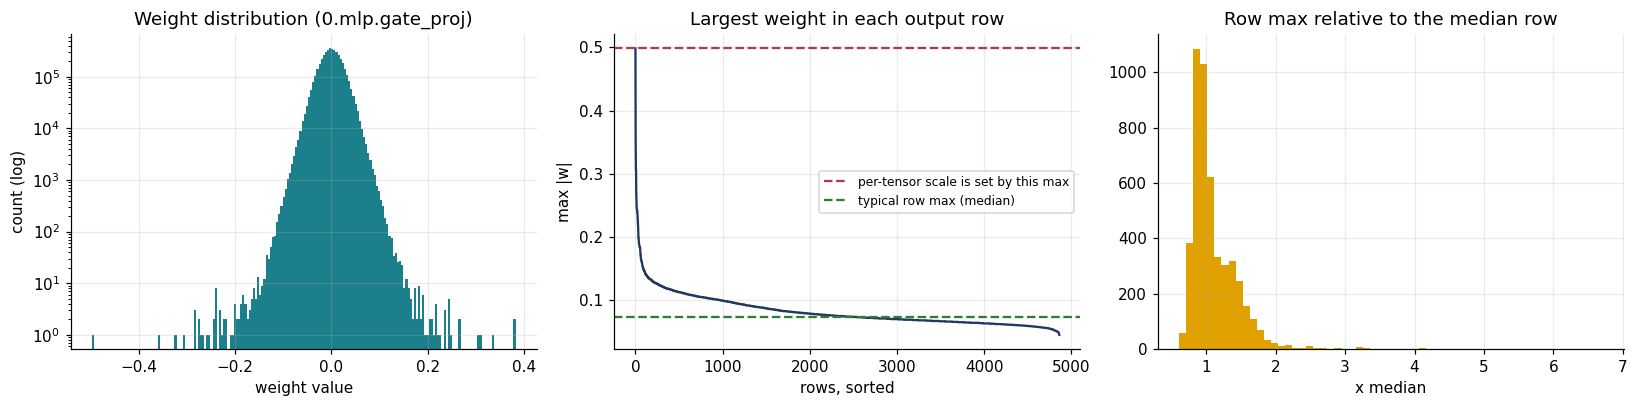

The largest weight in this matrix is 6.7x the median row maximum. The bigger this ratio, the more resolution a single per-tensor scale wastes on typical rows.


In [13]:
probe_name = [n for n, m in base.named_modules() if n.endswith("layers.0.mlp.up_proj") or n.endswith("layers.0.mlp.gate_proj")][0]
W = dict(base.named_modules())[probe_name].weight.detach().float().cpu()
row_absmax = W.abs().amax(1).numpy()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(W.flatten().numpy(), bins=200, color="#1B7F8C"); ax[0].set_yscale("log")
ax[0].set_title(f"Weight distribution ({probe_name.split('.', 2)[-1]})"); ax[0].set_xlabel("weight value"); ax[0].set_ylabel("count (log)")
ax[1].plot(np.sort(row_absmax)[::-1], color="#1F3A5F"); ax[1].axhline(row_absmax.max(), color="#B23A48", ls="--", label="per-tensor scale is set by this max")
ax[1].axhline(np.median(row_absmax), color="#2E7D32", ls="--", label="typical row max (median)")
ax[1].set_title("Largest weight in each output row"); ax[1].set_xlabel("rows, sorted"); ax[1].set_ylabel("max |w|"); ax[1].legend(fontsize=8)
ax[2].hist(row_absmax / np.median(row_absmax), bins=60, color="#E0A100"); ax[2].set_title("Row max relative to the median row"); ax[2].set_xlabel("x median")
plt.tight_layout(); plt.show()
print(f"The largest weight in this matrix is {row_absmax.max() / np.median(row_absmax):.1f}x the median row maximum. The bigger this ratio, the more resolution a single per-tensor scale wastes on typical rows.")

,config,scheme,SQNR (dB),mean |error|,max |error|
0,W8 per-tensor,sym,26.32,0.000981,0.001953
1,W8 per-channel,sym,41.45,0.000163,0.001953
2,W4 per-tensor,asym,3.28,0.013671,0.029297
3,W4 per-channel,asym,17.55,0.002575,0.029297
4,W4 group-128,asym,19.72,0.002021,0.022888
5,W4 group-128 +clip,asym,20.20,0.001868,0.044189
6,W2 group-64,asym,6.70,0.009058,0.069946


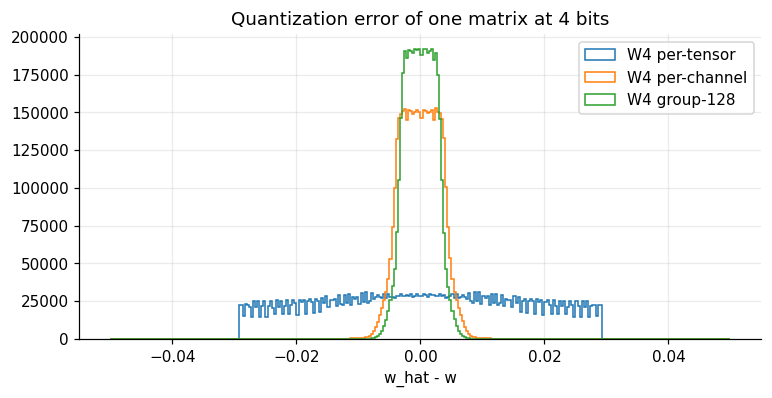

In [14]:
# Quantize this one matrix with every scheme and compare the reconstruction error
probe = []
for name, cfg in CONFIGS.items():
    ql = QuantLinear.from_float(W, None, cfg); err = (ql.dequantize(torch.float32) - W)
    probe.append({"config": cfg.label, "scheme": cfg.scheme, "SQNR (dB)": round(sqnr(W, W + err), 2), "mean |error|": err.abs().mean().item(), "max |error|": err.abs().max().item()})
display(pd.DataFrame(probe))

fig, ax = plt.subplots(1, 1, figsize=(8, 3.6))
for name in ("w4_per_tensor", "w4_per_channel", "w4_g128"):
    e = (QuantLinear.from_float(W, None, CONFIGS[name]).dequantize(torch.float32) - W).flatten().numpy()
    ax.hist(e, bins=300, range=(-0.05, 0.05), histtype="step", lw=1.6, label=CONFIGS[name].label)
ax.set_title("Quantization error of one matrix at 4 bits"); ax.set_xlabel("w_hat - w"); ax.legend(); plt.show()

## 6. Run the 7 experiments
For every configuration the notebook copies the FP16 model, quantizes it, and measures: **size** (from the stored tensors), **weight SQNR**, **perplexity** on WikiText-2,
**decoding speed** and **peak GPU memory**. Layer-level SQNR is kept for the charts.
Quality target: perplexity at most `FP16 x (1 + PPL_TOL)`; size target: at least `SIZE_TARGET` smaller.

In [15]:
def measure(model):
    if device.type == "cuda": torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    ppl = perplexity(model, ids, device, SEQ_LEN, BATCH_SIZE, MAX_EVAL_TOKENS)
    tps = decode_speed(model, prompt, device, SPEED_TOKENS, SPEED_RUNS)
    peak = torch.cuda.max_memory_allocated() / MB if device.type == "cuda" else float("nan")
    return ppl, tps, peak

print("== FP16 baseline ==")
m = copy.deepcopy(base).to(device)
BASE_PPL, BASE_TPS, BASE_PEAK = measure(m); del m
print(f"perplexity {BASE_PPL:.3f} | {BASE_TPS:.1f} tok/s | size {FP16_BYTES / MB:.0f} MB")
PPL_LIMIT = BASE_PPL * (1 + PPL_TOL); SIZE_LIMIT_MB = FP16_BYTES * (1 - SIZE_TARGET) / MB
print(f"=> size limit {SIZE_LIMIT_MB:.0f} MB, perplexity limit {PPL_LIMIT:.2f}")

== FP16 baseline ==
perplexity 17.194 | 25.4 tok/s | size 942 MB
=> size limit 377 MB, perplexity limit 19.77


In [16]:
records, layer_records = [], []
for name, cfg in CONFIGS.items():
    t0 = time.time(); m = copy.deepcopy(base).to(device)
    stats = convert(m, cfg, quantize_embeddings=True); qtime = time.time() - t0
    size = model_size_bytes(m); ppl, tps, peak = measure(m)
    red = 1 - size / FP16_BYTES
    records.append({"name": name, "config": cfg.label, "bits": cfg.bits, "granularity": cfg.granularity, "group_size": cfg.group_size if cfg.granularity == "group" else None,
                    "scheme": cfg.scheme, "clip": cfg.clip_search, "size_mb": size / MB, "smaller_pct": 100 * red, "bits_per_weight": stats["bits_per_weight"],
                    "sqnr_db": stats["sqnr_db"], "ppl": ppl, "ppl_change_pct": 100 * (ppl / BASE_PPL - 1), "tok_s": tps, "peak_mem_mb": peak,
                    "quantize_s": qtime, "meets_size": red >= SIZE_TARGET, "meets_quality": ppl <= PPL_LIMIT})
    for l in stats["layers"]:
        layer_records.append({"config": cfg.label, "layer": l["name"], "kind": l["name"].split(".")[-1], "sqnr_db": l["sqnr_db"],
                              "depth": int(l["name"].split("layers.")[1].split(".")[0]) if "layers." in l["name"] else -1})
    print(f"{cfg.label:<22} size {size / MB:6.0f} MB ({100 * red:4.1f}% smaller) | SQNR {stats['sqnr_db']:5.1f} dB | ppl {ppl:>14,.2f} ({100 * (ppl / BASE_PPL - 1):+.1f}%) | {tps:5.1f} tok/s")
    del m
    if device.type == "cuda": torch.cuda.empty_cache()
print("done")

W8 per-tensor          size    472 MB (50.0% smaller) | SQNR  25.6 dB | ppl          18.03 (+4.9%) |  11.9 tok/s
W8 per-channel         size    472 MB (49.9% smaller) | SQNR  40.0 dB | ppl          17.24 (+0.2%) |  13.4 tok/s
W4 per-tensor          size    301 MB (68.1% smaller) | SQNR   3.2 dB | ppl  10,446,818.97 (+60758365.7%) |  10.5 tok/s
W4 per-channel         size    302 MB (68.0% smaller) | SQNR  16.3 dB | ppl          30.79 (+79.1%) |  10.5 tok/s
W4 group-128           size    309 MB (67.2% smaller) | SQNR  19.3 dB | ppl          20.65 (+20.1%) |  10.3 tok/s
W4 group-128 +clip     size    309 MB (67.2% smaller) | SQNR  19.8 dB | ppl          21.04 (+22.4%) |  10.5 tok/s
W2 group-64            size    232 MB (75.4% smaller) | SQNR   6.5 dB | ppl     163,940.04 (+953371.6%) |   9.6 tok/s
done


### 6.1 Results table (saved as CSV)

In [17]:
results = pd.DataFrame(records)
layer_df = pd.DataFrame(layer_records)
baseline_row = pd.DataFrame([{"name": "fp16", "config": "FP16 baseline", "bits": 16, "scheme": "-", "size_mb": FP16_BYTES / MB, "smaller_pct": 0.0, "bits_per_weight": 16.0,
                              "ppl": BASE_PPL, "ppl_change_pct": 0.0, "tok_s": BASE_TPS, "peak_mem_mb": BASE_PEAK}])
full = pd.concat([baseline_row, results], ignore_index=True)
full.to_csv("results.csv", index=False)             # all configs + baseline
layer_df.to_csv("layer_sqnr.csv", index=False)      # layer-level error
show = full[["config", "scheme", "size_mb", "smaller_pct", "bits_per_weight", "sqnr_db", "ppl", "ppl_change_pct", "tok_s", "peak_mem_mb", "meets_size", "meets_quality"]]
display(show.style.format({"size_mb": "{:.0f}", "smaller_pct": "{:.1f}%", "bits_per_weight": "{:.2f}", "sqnr_db": "{:.1f}", "ppl": "{:,.2f}", "ppl_change_pct": "{:+,.1f}%",
                           "tok_s": "{:.1f}", "peak_mem_mb": "{:,.0f}"}, na_rep="-").background_gradient(subset=["ppl_change_pct"], cmap="RdYlGn_r", vmin=0, vmax=100))
print("saved: results.csv, layer_sqnr.csv")

,config,scheme,size_mb,smaller_pct,bits_per_weight,sqnr_db,ppl,ppl_change_pct,tok_s,peak_mem_mb,meets_size,meets_quality
0,FP16 baseline,-,942,0.0%,16.00,-,17.19,+0.0%,25.4,"3,923",-,-
1,W8 per-tensor,sym,472,50.0%,8.00,25.6,18.03,+4.9%,11.9,"3,444",False,True
2,W8 per-channel,sym,472,49.9%,8.01,40.0,17.24,+0.2%,13.4,"3,445",False,True
3,W4 per-tensor,asym,301,68.1%,4.00,3.2,"10,446,818.97","+60,758,365.7%",10.5,"3,274",True,False
4,W4 per-channel,asym,302,68.0%,4.02,16.3,30.79,+79.1%,10.5,"3,275",True,False
5,W4 group-128,asym,309,67.2%,4.19,19.3,20.65,+20.1%,10.3,"3,282",True,False
6,W4 group-128 +clip,asym,309,67.2%,4.19,19.8,21.04,+22.4%,10.5,"3,282",True,False
7,W2 group-64,asym,232,75.4%,2.38,6.5,"163,940.04","+953,371.6%",9.6,"3,209",True,False


saved: results.csv, layer_sqnr.csv


## 7. Visualisations

### 7.1 Quality versus size (the constraint)
The green zone is *small enough*; below the red line is *good enough*. A configuration must be in the green zone **and** below the red line.

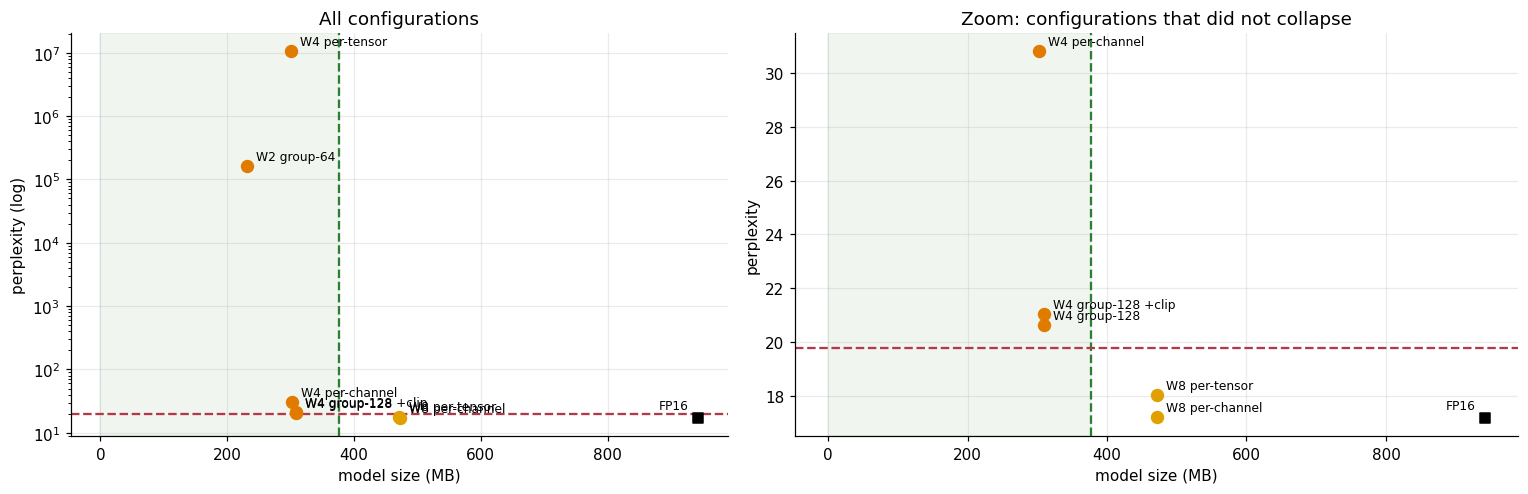

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.1]})
def verdict_color(r): return "#2E7D32" if r.meets_size and r.meets_quality else ("#E07B00" if r.meets_size else "#E0A100")
for ax, zoom in zip(axs, (False, True)):
    ax.axvspan(0, SIZE_LIMIT_MB, color="#2e7d32", alpha=0.07); ax.axvline(SIZE_LIMIT_MB, color="#2e7d32", ls="--"); ax.axhline(PPL_LIMIT, color="#B23A48", ls="--")
    ax.scatter([FP16_BYTES / MB], [BASE_PPL], marker="s", color="black", zorder=4); ax.annotate("FP16", (FP16_BYTES / MB, BASE_PPL), textcoords="offset points", xytext=(-6, 6), ha="right", fontsize=8)
    for _, r in results.iterrows():
        if zoom and r.ppl > 2 * PPL_LIMIT: continue
        ax.scatter([r.size_mb], [r.ppl], color=verdict_color(r), s=60, zorder=4); ax.annotate(r.config, (r.size_mb, r.ppl), textcoords="offset points", xytext=(6, 4), fontsize=8)
    ax.set_xlabel("model size (MB)"); ax.set_ylabel("perplexity" + ("" if zoom else " (log)"))
    if not zoom: ax.set_yscale("log"); ax.set_title("All configurations")
    else: ax.set_title("Zoom: configurations that did not collapse")
plt.tight_layout(); plt.show()

### 7.2 Weight error and speed

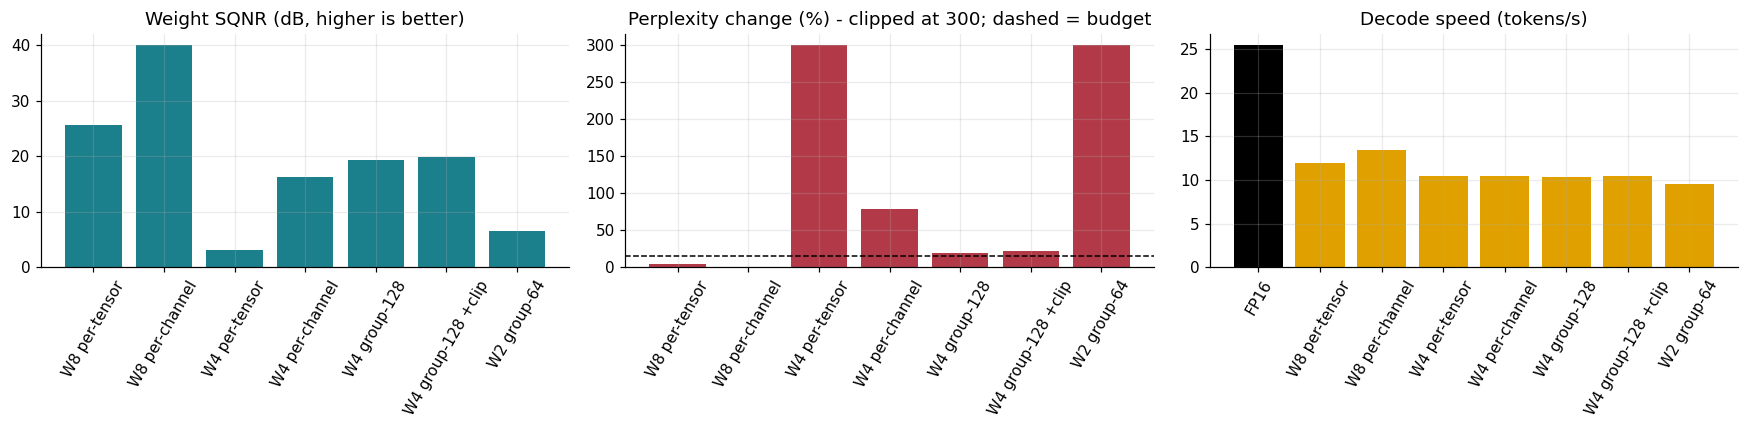

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
lab = results.config
axs[0].bar(lab, results.sqnr_db, color="#1B7F8C"); axs[0].set_title("Weight SQNR (dB, higher is better)"); axs[0].tick_params(axis="x", rotation=60)
axs[1].bar(lab, results.ppl_change_pct.clip(upper=300), color="#B23A48"); axs[1].axhline(100 * PPL_TOL, color="black", ls="--", lw=1)
axs[1].set_title("Perplexity change (%) - clipped at 300; dashed = budget"); axs[1].tick_params(axis="x", rotation=60)
axs[2].bar(["FP16"] + list(lab), [BASE_TPS] + list(results.tok_s), color=["black"] + ["#E0A100"] * len(lab)); axs[2].set_title("Decode speed (tokens/s)"); axs[2].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

### 7.3 Where does the error live? Layer type and depth

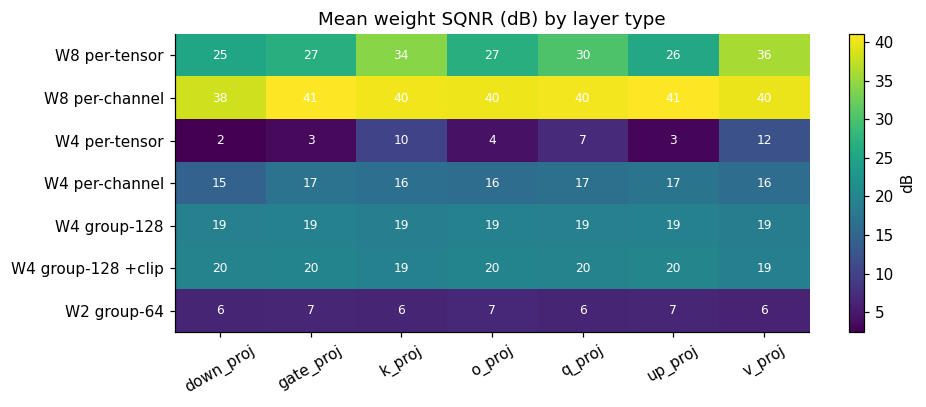

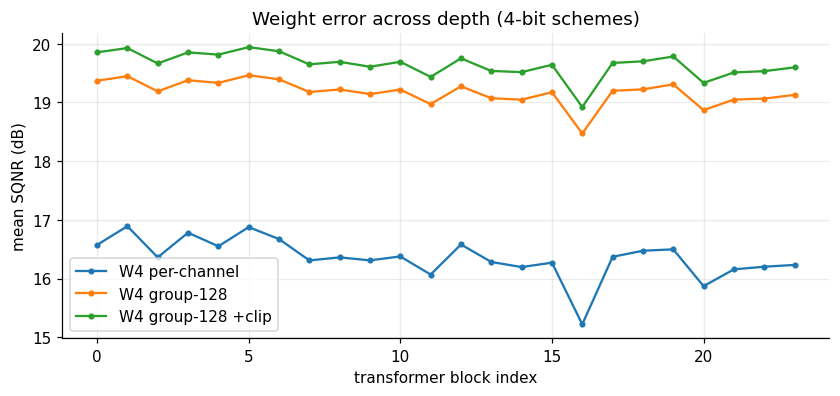

In [20]:
heat = layer_df.pivot_table(index="config", columns="kind", values="sqnr_db", aggfunc="mean").reindex([c.label for c in CONFIGS.values()])
fig, ax = plt.subplots(figsize=(9, 3.8)); im = ax.imshow(heat.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, rotation=30); ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index); ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]): ax.text(j, i, f"{heat.values[i, j]:.0f}", ha="center", va="center", color="white", fontsize=8)
ax.set_title("Mean weight SQNR (dB) by layer type"); plt.colorbar(im, label="dB"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
for name in ("w4_per_channel", "w4_g128", "w4_g128_clip"):
    d = layer_df[(layer_df.config == CONFIGS[name].label) & (layer_df.depth >= 0)].groupby("depth").sqnr_db.mean(); ax.plot(d.index, d.values, marker="o", ms=3, label=CONFIGS[name].label)
ax.set_xlabel("transformer block index"); ax.set_ylabel("mean SQNR (dB)"); ax.set_title("Weight error across depth (4-bit schemes)"); ax.legend(); plt.show()

### 7.4 Memory: bytes saved in the weights versus peak GPU memory

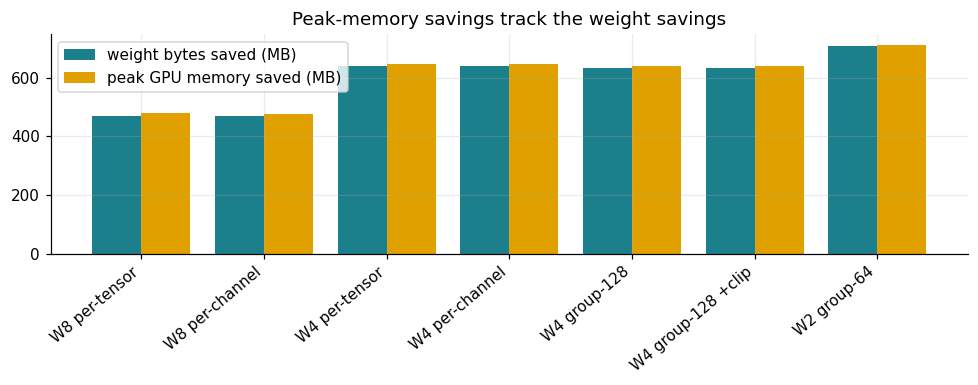

In [21]:
if results.peak_mem_mb.notna().all():
    saved_w = FP16_BYTES / MB - results.size_mb; saved_p = BASE_PEAK - results.peak_mem_mb
    x = np.arange(len(results)); fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.bar(x - 0.2, saved_w, 0.4, label="weight bytes saved (MB)", color="#1B7F8C"); ax.bar(x + 0.2, saved_p, 0.4, label="peak GPU memory saved (MB)", color="#E0A100")
    ax.set_xticks(x); ax.set_xticklabels(results.config, rotation=40, ha="right"); ax.legend(); ax.set_title("Peak-memory savings track the weight savings"); plt.tight_layout(); plt.show()
else:
    print("Peak GPU memory is only measured on a GPU runtime - skipped.")

### 7.5 Theory versus measurement: bits per weight
`bits per weight = b + (16 + 8) / G` for asymmetric schemes (FP16 scale + uint8 zero per group of `G` weights) and `b + 16 / G` for symmetric ones.

In [22]:
def theory_bpw(r):
    G = {"per_tensor": float("inf"), "per_channel": 2000, "group": r.group_size}[r.granularity]   # per-channel rows are 896..4864 long
    return r.bits + (16 if r.scheme == "sym" else 24) / G
tb = results.assign(theory=results.apply(theory_bpw, axis=1))[["config", "theory", "bits_per_weight"]]
display(tb.style.format({"theory": "{:.3f}", "bits_per_weight": "{:.3f}"}))

,config,theory,bits_per_weight
0,W8 per-tensor,8.000,8.000
1,W8 per-channel,8.008,8.014
2,W4 per-tensor,4.000,4.000
3,W4 per-channel,4.012,4.020
4,W4 group-128,4.188,4.188
5,W4 group-128 +clip,4.188,4.188
6,W2 group-64,2.375,2.375


## 8. Pick the winner
Rule: keep configurations that are at least `SIZE_TARGET` smaller **and** within `PPL_TOL` perplexity; choose the lowest perplexity.
If none qualifies, fall back to the best configuration that meets the size target, and say so.

In [23]:
both = results[results.meets_size & results.meets_quality]; size_only = results[results.meets_size]
if len(both): winner, status = both.sort_values("ppl").iloc[0], "meets both constraints"
elif len(size_only): winner, status = size_only.sort_values("ppl").iloc[0], "meets the size target only (quality budget missed)"
else: winner, status = results.sort_values("size_mb").iloc[0], "meets neither constraint (smallest model)"
WINNER = winner["name"]
display(Markdown(f"""### Winner: **{winner.config}** ({winner.scheme}) - {status}
- **Size:** {winner.size_mb:.0f} MB vs {FP16_BYTES / MB:.0f} MB for FP16 ({winner.smaller_pct:.1f}% smaller, {winner.bits_per_weight:.2f} bits per weight)
- **Quality:** perplexity {winner.ppl:.2f} vs {BASE_PPL:.2f} for FP16 ({winner.ppl_change_pct:+.1f}%), budget {PPL_LIMIT:.2f}; weight SQNR {winner.sqnr_db:.1f} dB
- **Speed:** {winner.tok_s:.1f} tok/s vs {BASE_TPS:.1f} for FP16 ({winner.tok_s / BASE_TPS:.2f}x) - on-the-fly dequantization in plain PyTorch saves memory, not latency
"""))
display(results.assign(verdict=np.where(results.meets_size & results.meets_quality, "meets both", np.where(results.meets_size, "size ok, quality fails", "quality ok, size fails")))
        [["config", "size_mb", "smaller_pct", "ppl", "ppl_change_pct", "verdict"]].round(2))

### Winner: **W4 group-128** (asym) - meets the size target only (quality budget missed)
- **Size:** 309 MB vs 942 MB for FP16 (67.2% smaller, 4.19 bits per weight)
- **Quality:** perplexity 20.65 vs 17.19 for FP16 (+20.1%), budget 19.77; weight SQNR 19.3 dB
- **Speed:** 10.3 tok/s vs 25.4 for FP16 (0.41x) - on-the-fly dequantization in plain PyTorch saves memory, not latency


,config,size_mb,smaller_pct,ppl,ppl_change_pct,verdict
0,W8 per-tensor,471.50,49.96,18.03,4.87,"quality ok, size fails"
1,W8 per-channel,472.08,49.90,17.24,0.24,"quality ok, size fails"
2,W4 per-tensor,300.88,68.07,10446818.97,60758365.66,"size ok, quality fails"
3,W4 per-channel,301.75,67.98,30.79,79.06,"size ok, quality fails"
4,W4 group-128,308.88,67.22,20.65,20.11,"size ok, quality fails"
5,W4 group-128 +clip,308.88,67.22,21.04,22.35,"size ok, quality fails"
6,W2 group-64,231.56,75.43,163940.04,953371.60,"size ok, quality fails"


## 9. Export and publish the quantized winner
This re-quantizes the winning configuration from the FP16 model, saves it as `model.safetensors` + `quant_config.json` + config + tokenizer in `hf_model/`,
**reloads it and compares logits** (the model is only published if the reload matches), and writes a model card.
Hugging Face cannot load this custom packed format with `from_pretrained`, so the model card points to this notebook's `load_quantized`.

In [24]:
# --------------------------------------------------------------------------- #
# Save / load (so the quantized model can live on the Hugging Face Hub)
# --------------------------------------------------------------------------- #
def save_quantized(model, tokenizer, cfg: QConfig, path: str, quantize_embeddings=True,
                   base_model: str = ""):
    from safetensors.torch import save_file
    os.makedirs(path, exist_ok=True)
    sd = {k: v.detach().cpu().contiguous() for k, v in model.state_dict().items()}
    save_file(sd, os.path.join(path, "model.safetensors"), metadata={"format": "pt"})
    model.config.save_pretrained(path)
    if tokenizer is not None:
        tokenizer.save_pretrained(path)
    qc = asdict(cfg)
    qc.update(quantize_embeddings=quantize_embeddings, base_model=base_model,
              dtype=str(next(p for p in model.parameters() if p.is_floating_point()).dtype).replace("torch.", ""))
    with open(os.path.join(path, "quant_config.json"), "w") as f:
        json.dump(qc, f, indent=2)


def load_quantized(path: str, device="cpu"):
    """Rebuild the architecture from config.json, swap in QuantLinear shells, load the packed weights."""
    from safetensors.torch import load_file
    from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
    with open(os.path.join(path, "quant_config.json")) as f:
        qc = json.load(f)
    dtype = getattr(torch, qc.pop("dtype"))
    quantize_embeddings, _ = qc.pop("quantize_embeddings"), qc.pop("base_model", None)
    cfg = QConfig(**qc)
    config = AutoConfig.from_pretrained(path)
    try:
        model = AutoModelForCausalLM.from_config(config, dtype=dtype)
    except TypeError:  # older transformers
        model = AutoModelForCausalLM.from_config(config, torch_dtype=dtype)
    convert(model, cfg, quantize_embeddings=quantize_embeddings, with_weights=False)
    model.load_state_dict(load_file(os.path.join(path, "model.safetensors")), strict=True)
    model.to(device).eval()
    try:
        tok = AutoTokenizer.from_pretrained(path)
    except Exception:
        tok = None
    return model, tok

In [27]:
cfg_w = CONFIGS[WINNER]
m = copy.deepcopy(base).to(device); convert(m, cfg_w); size_w = model_size_bytes(m)
save_quantized(m, tok, cfg_w, "hf_model", base_model=MODEL_ID)

test_ids = torch.randint(0, m.config.vocab_size, (1, 24), device=device)
with torch.no_grad(): ref = m(test_ids).logits.float()
loaded, _ = load_quantized("hf_model", device=device)
with torch.no_grad(): out = loaded(test_ids).logits.float()
diff = (ref - out).abs().max().item(); assert diff < 6e-2, f"reload mismatch {diff}"
print(f"{cfg_w.label}: {size_w / MB:.1f} MB ({100 * (1 - size_w / FP16_BYTES):.1f}% smaller) | reload check OK (max logit diff {diff:.2e})")
del m, loaded
print(sorted(os.listdir("hf_model")))

W4 group-128: 308.9 MB (67.2% smaller) | reload check OK (max logit diff 5.86e-02)
['chat_template.jinja', 'config.json', 'model.safetensors', 'quant_config.json', 'tokenizer.json', 'tokenizer_config.json']


In [28]:
card = f"""---
base_model: {MODEL_ID}
tags: [quantization, int4, pytorch, from-scratch]
---

# {MODEL_ID.split('/')[-1]} - {cfg_w.label} (custom from-scratch quantizer)

{MODEL_ID} quantized with a quantizer written in raw PyTorch (no bitsandbytes / torch.ao / GPTQ libraries).

| | |
|---|---|
| Config | {cfg_w.label} ({cfg_w.scheme}) |
| Size | {size_w / MB:.0f} MB (FP16: {FP16_BYTES / MB:.0f} MB, {100 * (1 - size_w / FP16_BYTES):.0f}% smaller) |
| WikiText-2 perplexity | {winner.ppl:.2f} (FP16: {BASE_PPL:.2f}) |
| Speed | {winner.tok_s:.1f} tok/s on {GPU_NAME} (FP16: {BASE_TPS:.1f}) |

## Format
Bit-packed `uint8` weights (`qweight`), FP16 scales (`scale`) and uint8 zero-points (`zero`) per row/group; the embedding table
(tied with the output head) is 8-bit per-row. Weights are dequantized on the fly in `QuantLinear.forward`.

## How to load
This is a custom packed format: `AutoModelForCausalLM.from_pretrained` will not work. Use the `QConfig`, `QuantLinear`, `QuantEmbedding`,
`convert` and `load_quantized` definitions from the project notebook, download this repo with `snapshot_download`, then call
`load_quantized(path, device="cuda")`. License: same as the base model.
"""
open("hf_model/README.md", "w").write(card); print("model card written")

model card written


### Push to Hugging Face
Create a **Write** token at huggingface.co/settings/tokens, log in, set `HF_REPO_ID` in the settings cell (format `username/model-name`, not a URL), then run both cells.

In [29]:
from huggingface_hub import notebook_login
notebook_login()

In [30]:
from huggingface_hub import HfApi
assert "YOUR_HF_USERNAME" not in HF_REPO_ID and "/" in HF_REPO_ID and not HF_REPO_ID.startswith("http"), "Set HF_REPO_ID to  username/model-name  in the settings cell"
api = HfApi(); api.create_repo(HF_REPO_ID, exist_ok=True); api.upload_folder(folder_path="hf_model", repo_id=HF_REPO_ID)
print("pushed: https://huggingface.co/" + HF_REPO_ID)

pushed: https://huggingface.co/EliasTad/qwen2.5-0.5b-w4-custom-quant


## 10. Conclusions
Read the numbers above together:
- **Scaling granularity matters more than one extra bit.** One scale per tensor collapses a 4-bit model; per-channel rescues part of it; group-wise scaling is the best 4-bit option for a small 0.19 bits-per-weight overhead.
- **Lower weight error is not always a better model.** Compare SQNR and perplexity for the clipping-search configuration.
- **2-bit without calibration is not viable** at this model size.
- **Memory versus speed:** weights shrink and peak memory drops by the same amount, but on-the-fly dequantization in plain PyTorch is slower than FP16. Fused kernels would be needed for speed.
- **Next steps:** smaller groups, mixed precision (keep sensitive layers at 8 bits), calibration-based rounding (GPTQ/AWQ-style), broader evaluation.

Files written by this notebook: `results.csv`, `layer_sqnr.csv`, and the `hf_model/` folder (needed by Hugging Face).